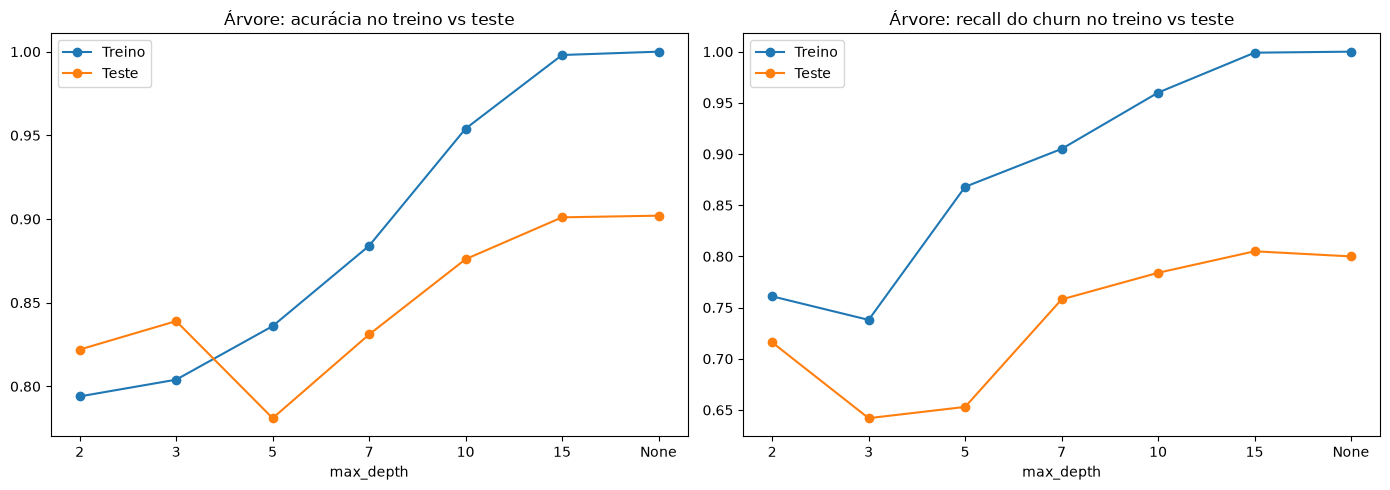

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = range(len(tab_arvore))

ax[0].plot(x, tab_arvore["acc_treino"], marker="o", label="Treino")
ax[0].plot(x, tab_arvore["acc_teste"], marker="o", label="Teste")
ax[0].set_xticks(list(x))
ax[0].set_xticklabels(tab_arvore.index)
ax[0].set_title("Árvore: acurácia no treino vs teste")
ax[0].set_xlabel("max_depth")
ax[0].legend()

ax[1].plot(x, tab_arvore["recall_treino"], marker="o", label="Treino")
ax[1].plot(x, tab_arvore["recall_teste"], marker="o", label="Teste")
ax[1].set_xticks(list(x))
ax[1].set_xticklabels(tab_arvore.index)
ax[1].set_title("Árvore: recall do churn no treino vs teste")
ax[1].set_xlabel("max_depth")
ax[1].legend()

plt.tight_layout()
plt.show()

In [12]:
resultados_arvore = []
for prof in [2, 3, 5, 7, 10, 15, None]:
    r = avaliar(DecisionTreeClassifier(max_depth=prof, random_state=42),
                X_train_bal, y_train_bal, X_test, y_test)
    r["max_depth"] = "None" if prof is None else str(prof)
    resultados_arvore.append(r)

tab_arvore = pd.DataFrame(resultados_arvore).set_index("max_depth").round(3)
tab_arvore["gap_acc"] = (tab_arvore["acc_treino"] - tab_arvore["acc_teste"]).round(3)
tab_arvore["gap_recall"] = (tab_arvore["recall_treino"] - tab_arvore["recall_teste"]).round(3)
tab_arvore

,acc_treino,acc_teste,recall_treino,recall_teste,precisao_teste,f1_teste,gap_acc,gap_recall
max_depth,,,,,,,,
2,0.794,0.822,0.761,0.716,0.482,0.576,-0.028,0.045
3,0.804,0.839,0.738,0.642,0.519,0.574,-0.035,0.096
5,0.836,0.781,0.868,0.653,0.407,0.501,0.055,0.215
7,0.884,0.831,0.905,0.758,0.500,0.603,0.053,0.147
10,0.954,0.876,0.960,0.784,0.601,0.680,0.078,0.176
15,0.998,0.901,0.999,0.805,0.674,0.734,0.097,0.194
None,1.000,0.902,1.000,0.800,0.679,0.734,0.098,0.200


### 5.2 Otimização da Árvore de Decisão (variando max_depth)

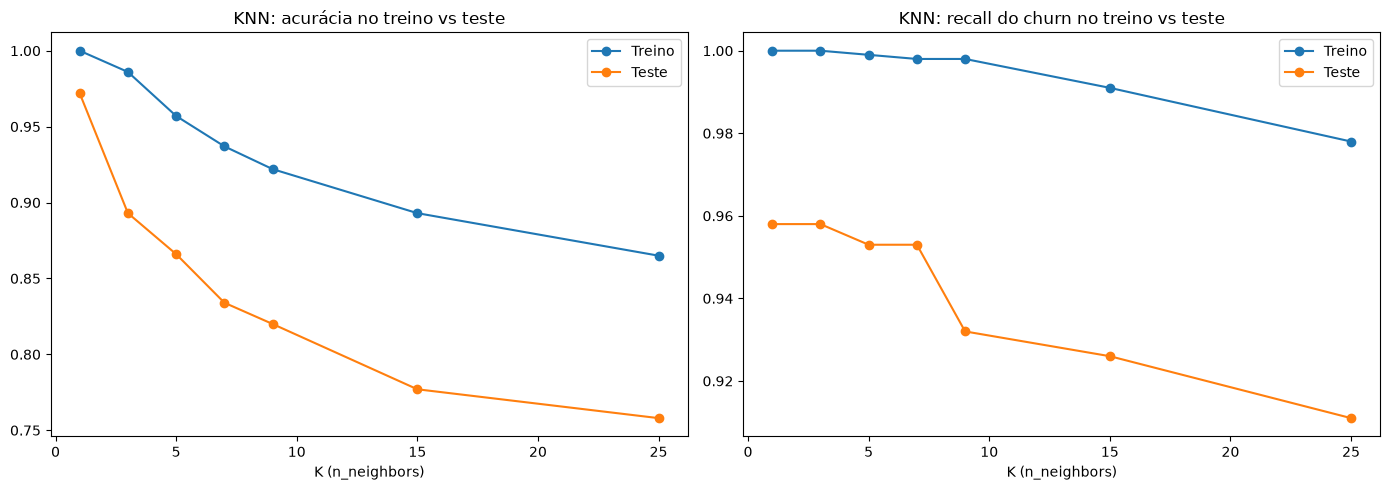

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(tab_knn.index, tab_knn["acc_treino"], marker="o", label="Treino")
ax[0].plot(tab_knn.index, tab_knn["acc_teste"], marker="o", label="Teste")
ax[0].set_title("KNN: acurácia no treino vs teste")
ax[0].set_xlabel("K (n_neighbors)")
ax[0].legend()

ax[1].plot(tab_knn.index, tab_knn["recall_treino"], marker="o", label="Treino")
ax[1].plot(tab_knn.index, tab_knn["recall_teste"], marker="o", label="Teste")
ax[1].set_title("KNN: recall do churn no treino vs teste")
ax[1].set_xlabel("K (n_neighbors)")
ax[1].legend()

plt.tight_layout()
plt.show()

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

def avaliar(modelo, X_tr, y_tr, X_te, y_te):
    modelo.fit(X_tr, y_tr)
    p_tr, p_te = modelo.predict(X_tr), modelo.predict(X_te)
    return {
        "acc_treino": accuracy_score(y_tr, p_tr),
        "acc_teste": accuracy_score(y_te, p_te),
        "recall_treino": recall_score(y_tr, p_tr),
        "recall_teste": recall_score(y_te, p_te),
        "precisao_teste": precision_score(y_te, p_te),
        "f1_teste": f1_score(y_te, p_te),
    }

resultados_knn = []
for k in [1, 3, 5, 7, 9, 15, 25]:
    r = avaliar(KNeighborsClassifier(n_neighbors=k), X_train_knn, y_train_bal, X_test_knn, y_test)
    r["K"] = k
    resultados_knn.append(r)

tab_knn = pd.DataFrame(resultados_knn).set_index("K").round(3)
tab_knn["gap_acc"] = (tab_knn["acc_treino"] - tab_knn["acc_teste"]).round(3)
tab_knn["gap_recall"] = (tab_knn["recall_treino"] - tab_knn["recall_teste"]).round(3)
tab_knn

,acc_treino,acc_teste,recall_treino,recall_teste,precisao_teste,f1_teste,gap_acc,gap_recall
K,,,,,,,,
1,1.000,0.972,1.000,0.958,0.883,0.919,0.028,0.042
3,0.986,0.893,1.000,0.958,0.619,0.752,0.093,0.042
5,0.957,0.866,0.999,0.953,0.560,0.706,0.091,0.046
7,0.937,0.834,0.998,0.953,0.504,0.659,0.103,0.045
9,0.922,0.820,0.998,0.932,0.482,0.636,0.102,0.066
15,0.893,0.777,0.991,0.926,0.426,0.584,0.116,0.065
25,0.865,0.758,0.978,0.911,0.404,0.560,0.107,0.067


## Fase 5: Modelagem e Validação (O Desafio do Overfitting)

### 5.1 Otimização do KNN (variando K)

**Decisão:** o `StandardScaler` foi ajustado (`fit`) somente no treino balanceado e apenas aplicado (`transform`) no teste, para que o teste não influencie a média e o desvio padrão (data leakage). Ele foi aplicado só às variáveis numéricas não binárias, e não às dummies 0/1 nem à coluna Complain. O KNN usa distâncias euclidianas, então variáveis de escala grande (como CashbackAmount, na casa das centenas) dominariam as pequenas. A **Árvore de Decisão** faz cortes do tipo "variável ≤ valor", que dependem só da ordem dos valores e não da escala, por isso ela será treinada com `X_train_bal`, **sem escalonamento**. A célula anterior comprova: as previsões da árvore são idênticas com e sem escala.

In [9]:
from sklearn.tree import DecisionTreeClassifier

arvore_sem_escala = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train_bal, y_train_bal)
arvore_com_escala = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train_knn, y_train_bal)

pred_sem = arvore_sem_escala.predict(X_test)
pred_com = arvore_com_escala.predict(X_test_knn)

print("Previsões idênticas com e sem escalonamento:", (pred_sem == pred_com).all())
print("Acurácia sem escalonamento:", round((pred_sem == y_test).mean(), 4))
print("Acurácia com escalonamento:", round((pred_com == y_test).mean(), 4))

Previsões idênticas com e sem escalonamento: True
Acurácia sem escalonamento: 0.7806
Acurácia com escalonamento: 0.7806


In [8]:
from sklearn.preprocessing import StandardScaler

colunas_continuas = ["Tenure", "WarehouseToHome", "HourSpendOnApp", "NumberOfDeviceRegistered",
                     "SatisfactionScore", "NumberOfAddress", "OrderAmountHikeFromlastYear",
                     "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount",
                     "cashback_por_pedido", "CityTier"]

# Versão ESCALONADA (para o KNN)
scaler = StandardScaler()
X_train_knn = X_train_bal.copy()
X_test_knn = X_test.copy()
X_train_knn[colunas_continuas] = scaler.fit_transform(X_train_bal[colunas_continuas])
X_test_knn[colunas_continuas] = scaler.transform(X_test[colunas_continuas])

# Versão SEM escalonamento (para a Árvore): X_train_bal e X_test

print("Média das colunas escalonadas no treino (≈0):", X_train_knn[colunas_continuas].mean().abs().max().round(2))
print("Desvio padrão no treino (≈1):", X_train_knn[colunas_continuas].std().round(2).max())

Média das colunas escalonadas no treino (≈0): 0.0
Desvio padrão no treino (≈1): 1.0


In [ ]:
### 4.3 Escalonamento seguro

**Decisão:** o split foi 80/20 com `stratify=y`, preservando a proporção de ~16,8% de churn nos dois conjuntos. O **SMOTE foi aplicado depois do split e somente no treino**: ele cria clientes sintéticos da classe minoritária interpolando vizinhos. O teste mantém a proporção original, simulando o mundo real. Balancear antes do split vazaria informação do teste para o treino (data leakage) e inflaria as métricas. Escolhi SMOTE em vez de Random Under Sampling para não descartar clientes da classe majoritária.

In [7]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df_enc.drop(columns="Churn")
y = df_enc["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Proporção de Churn no treino:", y_train.mean().round(3))
print("Proporção de Churn no teste: ", y_test.mean().round(3))
print("\nTreino antes do balanceamento:\n", y_train.value_counts())

# SMOTE somente no treino
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("\nTreino depois do SMOTE:\n", y_train_bal.value_counts())
print("\nTeste (não foi alterado):", y_test.value_counts().to_dict())

Proporção de Churn no treino: 0.168
Proporção de Churn no teste:  0.169

Treino antes do balanceamento:
 Churn
0    3746
1     758
Name: count, dtype: int64

Treino depois do SMOTE:
 Churn
0    3746
1    3746
Name: count, dtype: int64

Teste (não foi alterado): {0: 936, 1: 190}


### 4.2 Split estratificado e balanceamento

**Decisão:** o CustomerID foi removido por ser apenas um identificador, sem poder preditivo, e poderia atrapalhar as distâncias do KNN. As cinco colunas de texto não têm ordem natural entre as categorias (ex.: formas de pagamento), então usei **One-Hot Encoding**, que evita o modelo interpretar uma ordem inexistente (o que o Label Encoding faria). O `drop_first=True` remove uma coluna redundante por variável.

In [6]:
df_modelo = df.drop(columns=["CustomerID"])

colunas_categoricas = df_modelo.select_dtypes(exclude="number").columns.tolist()
print("Colunas categóricas:", colunas_categoricas)

df_enc = pd.get_dummies(df_modelo, columns=colunas_categoricas, drop_first=True, dtype=int)
print("Shape após o encoding:", df_enc.shape)
df_enc.head()

Colunas categóricas: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
Shape após o encoding: (5630, 27)


,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,...,PreferredPaymentMode_Debit Card,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,Gender_Male,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single
0,1,4.0,3,6.0,3.000000,3,2,9,1,11.0,...,1,0,0,0,0,1,0,0,0,1
1,1,9.0,1,8.0,3.000000,4,3,7,1,15.0,...,0,0,1,1,0,0,1,0,0,1
2,1,9.0,1,30.0,2.000000,4,3,6,1,14.0,...,1,0,0,1,0,0,1,0,0,1
3,1,0.0,3,15.0,2.000000,4,5,8,0,23.0,...,1,0,0,1,0,1,0,0,0,1
4,1,0.0,1,12.0,2.931535,3,5,3,0,11.0,...,0,0,0,1,0,0,1,0,0,1


## Fase 4: Separação, Balanceamento e Escalonamento Seguro

### 4.1 Encoding

In [5]:
df["cashback_por_pedido"] = df["CashbackAmount"] / df["OrderCount"]

print("Nulos na nova coluna:", df["cashback_por_pedido"].isnull().sum())
print("Infinitos na nova coluna:", np.isinf(df["cashback_por_pedido"]).sum())
print()
print(df["cashback_por_pedido"].describe())
print("\nCorrelação com Churn:", round(df["cashback_por_pedido"].corr(df["Churn"]), 3))

Nulos na nova coluna: 0
Infinitos na nova coluna: 0

count    5630.000000
mean       95.544097
std        53.355622
min         0.000000
25%        57.333333
50%        87.000000
75%       129.000000
max       299.000000
Name: cashback_por_pedido, dtype: float64

Correlação com Churn: -0.057


In [ ]:
## Fase 3: Feature Engineering (Coluna Calculada)

Os nulos de CashbackAmount e OrderCount já foram tratados na Fase 2 (OrderCount não tem zeros após a imputação), evitando NaN ou infinitos no cálculo.

**Nova coluna:** `cashback_por_pedido = CashbackAmount / OrderCount`, o valor médio de cashback que o cliente recebe por pedido.

**Decisão sobre outliers:** Tenure, WarehouseToHome e DaySinceLastOrder têm poucos valores isolados e muito distantes (ex.: 127 na distância ao armazém, contra mediana de 14). Como o KNN usa distâncias euclidianas, esses valores distorceriam o cálculo, então apliquei **clipping** pelo limite do IQR (Q3 + 1,5·IQR), que mantém as linhas e só limita o extremo. Já CouponUsed, OrderCount e CashbackAmount foram **mantidas**: seus valores altos são comportamentos reais (clientes que compram muito) e representam mais de 10% das linhas, então limitá-los apagaria informação. A Árvore de Decisão é robusta a outliers, e o clipping não a prejudica; o KNN é o modelo que mais se beneficia do tratamento.

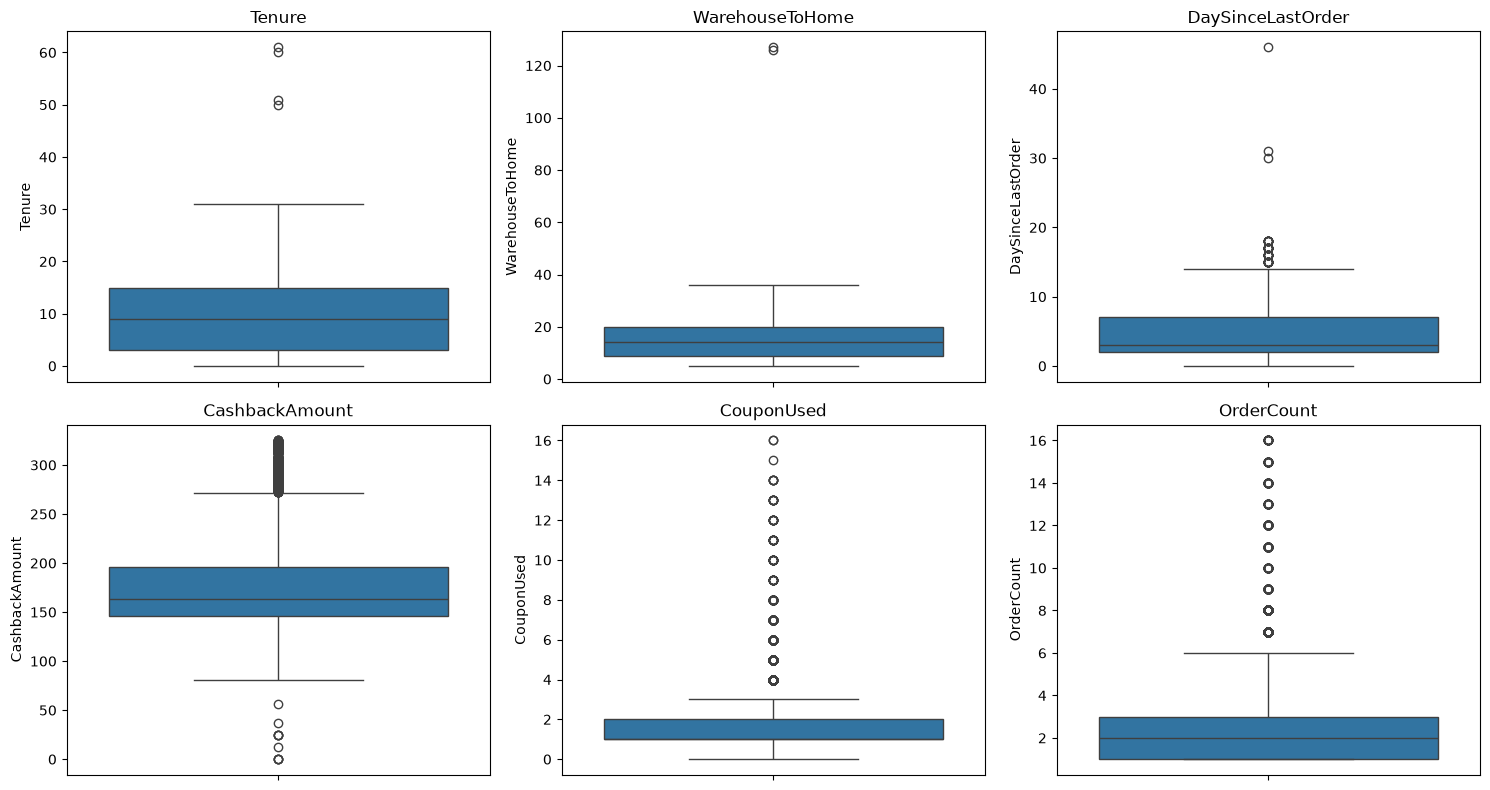

Tenure: 4 valores acima de 33.0 foram limitados
WarehouseToHome: 2 valores acima de 36.5 foram limitados
DaySinceLastOrder: 62 valores acima de 14.5 foram limitados


In [4]:
colunas_box = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount", "CouponUsed", "OrderCount"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), colunas_box):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Clipping pelos limites do IQR nas colunas com valores isolados e extremos
for col in ["Tenure", "WarehouseToHome", "DaySinceLastOrder"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    acima = (df[col] > limite_sup).sum()
    df[col] = df[col].clip(limite_inf, limite_sup)
    print(f"{col}: {acima} valores acima de {limite_sup:.1f} foram limitados")

### 2.3 Outliers

**Decisão sobre nulos:** cada coluna com nulos teve a técnica escolhida pela assimetria (skewness). HourSpendOnApp tem assimetria próxima de zero (distribuição simétrica), então usei a **média**. As outras seis (Tenure, WarehouseToHome, OrderAmountHikeFromlastYear, CouponUsed, OrderCount e DaySinceLastOrder) têm assimetria positiva acima de 0,5, com cauda longa à direita, então usei a **mediana**, que não é puxada pelos valores extremos. Imputar preserva as ~5% de linhas de cada coluna que seriam perdidas com a exclusão.

In [3]:
colunas_nulas = df.columns[df.isnull().any()]
assimetria = df[colunas_nulas].skew()
print("Assimetria (skewness) das colunas com nulos:")
print(assimetria.round(2))

# Regra: |assimetria| < 0.5 -> distribuição simétrica -> média; caso contrário -> mediana
for col in colunas_nulas:
    if abs(assimetria[col]) < 0.5:
        df[col] = df[col].fillna(df[col].mean())
        print(f"{col}: imputado com a MÉDIA")
    else:
        df[col] = df[col].fillna(df[col].median())
        print(f"{col}: imputado com a MEDIANA")

print("\nNulos restantes:", df.isnull().sum().sum())

Assimetria (skewness) das colunas com nulos:
Tenure                         0.74
WarehouseToHome                1.62
HourSpendOnApp                -0.03
OrderAmountHikeFromlastYear    0.79
CouponUsed                     2.55
OrderCount                     2.20
DaySinceLastOrder              1.19
dtype: float64
Tenure: imputado com a MEDIANA
WarehouseToHome: imputado com a MEDIANA
HourSpendOnApp: imputado com a MÉDIA
OrderAmountHikeFromlastYear: imputado com a MEDIANA
CouponUsed: imputado com a MEDIANA
OrderCount: imputado com a MEDIANA
DaySinceLastOrder: imputado com a MEDIANA

Nulos restantes: 0


### 2.2 Valores nulos

**Decisão sobre duplicadas:** não existem linhas 100% idênticas, pois o CustomerID é único. Porém, ao ignorar o CustomerID, 556 linhas são cópias exatas de outra linha em todos os 19 atributos (inclusive em variáveis numéricas como CashbackAmount e Tenure, o que torna improvável uma coincidência), sempre com o mesmo valor de Churn. Tratei essas linhas como registros redundantes e removi as cópias, mantendo uma ocorrência de cada. Mantê-las causaria vazamento de dados: após o split, uma cópia do cliente cairia no treino e a outra no teste, e o modelo (principalmente o KNN) "reconheceria" o cliente, inflando as métricas de teste.

**Padronização:** categorias com nomes diferentes e mesmo significado foram unificadas (Phone → Mobile Phone, CC → Credit Card, Cash on Delivery → COD, Mobile → Mobile Phone). Sem isso, o One-Hot Encoding criaria colunas duplicadas para a mesma informação.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/ecommerce_churn.csv")
print(df.shape)

(5630, 20)


In [ ]:
print("Duplicadas (linha inteira):", df.duplicated().sum())
colunas_sem_id = [c for c in df.columns if c != "CustomerID"]
print("Duplicadas ignorando CustomerID:", df.duplicated(subset=colunas_sem_id).sum())

df = df.drop_duplicates(subset=colunas_sem_id)

df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({"CC": "Credit Card", "Cash on Delivery": "COD"})
df["PreferedOrderCat"] = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

for col in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print(f"\n{col}:\n{df[col].value_counts()}")
print("\nShape após a limpeza:", df.shape)

Duplicadas (linha inteira): 0
Duplicadas ignorando CustomerID: 556

PreferredLoginDevice:
PreferredLoginDevice
Mobile Phone    3996
Computer        1634
Name: count, dtype: int64

PreferredPaymentMode:
PreferredPaymentMode
Debit Card     2314
Credit Card    1774
E wallet        614
COD             514
UPI             414
Name: count, dtype: int64

PreferedOrderCat:
PreferedOrderCat
Mobile Phone          2080
Laptop & Accessory    2050
Fashion                826
Grocery                410
Others                 264
Name: count, dtype: int64

Shape após a limpeza: (5630, 20)


## Fase 2: Tratamento e Limpeza (Data Prep)

### 2.1 Duplicadas e padronização de categorias

### 1.3 Interpretação e tomada de decisão

A base possui 5630 clientes e 20 colunas. A variável alvo é desbalanceada: apenas 16,8% dos clientes deram churn (Churn = 1) contra 83,2% que permaneceram. Isso significa que um modelo que sempre previsse "não vai sair" teria 83% de acurácia sem aprender nada, então a acurácia sozinha não serve como métrica e será necessário balancear as classes (somente no treino) e avaliar por Recall e Matriz de Confusão.

Sete colunas possuem valores nulos (Tenure, WarehouseToHome, HourSpendOnApp, OrderAmountHikeFromlastYear, CouponUsed, OrderCount e DaySinceLastOrder), entre 4,7% e 5,4% das linhas cada. Como são poucos, é melhor imputar do que excluir linhas. Também encontrei categorias escritas de formas diferentes com o mesmo significado (Phone/Mobile Phone, CC/Credit Card, COD/Cash on Delivery, Mobile/Mobile Phone), que precisam ser padronizadas antes do encoding para não criar colunas duplicadas.

No mapa de calor, as variáveis mais associadas ao churn são Tenure (correlação -0,35: clientes novos saem mais), Complain (+0,25: quem reclamou tem mais chance de sair), DaySinceLastOrder (-0,16) e CashbackAmount (-0,15). As demais têm correlação fraca com o alvo. Entre as variáveis preditoras, a maior correlação é entre CouponUsed e OrderCount (0,75), o que é esperado, já que quem faz mais pedidos usa mais cupons; as outras ficam abaixo de 0,50. Há, portanto, alguma redundância entre essas duas, mas como a Árvore de Decisão não exige variáveis independentes e o KNN não é afetado de forma grave, mantive ambas.

Várias variáveis têm assimetria à direita e valores extremos, como WarehouseToHome (máximo de 127 contra mediana de 14) e Tenure (máximo de 61 contra mediana de 9). Isso guiará a preparação: usar a mediana para imputar variáveis assimétricas, tratar os outliers (que distorcem as distâncias do KNN e pouco afetam a Árvore), padronizar as categorias, usar split estratificado, balancear apenas o treino e escalonar somente para o KNN.

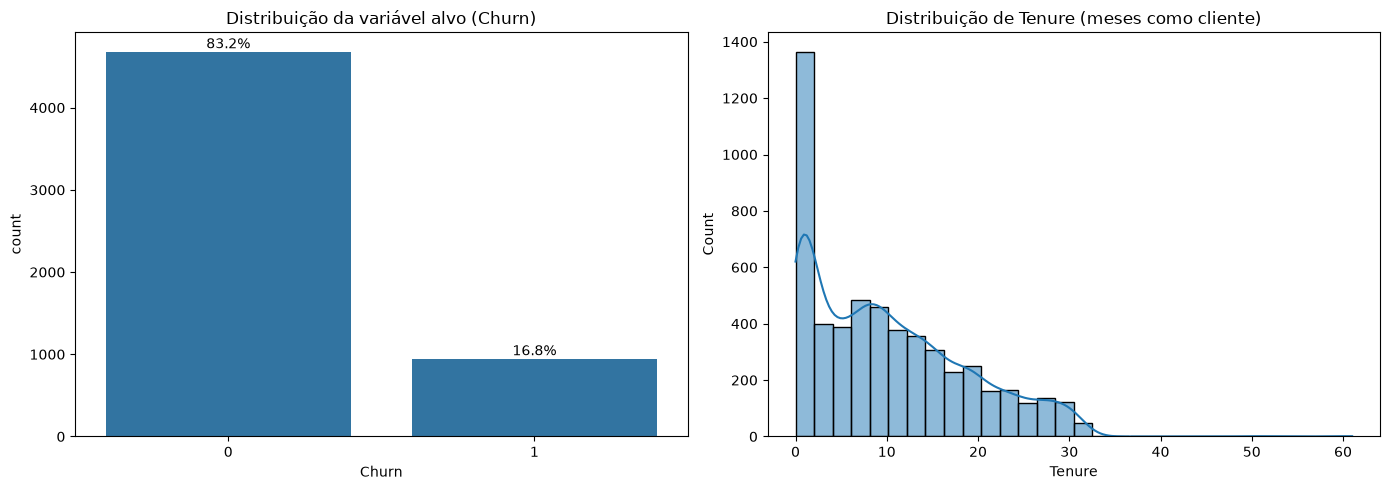

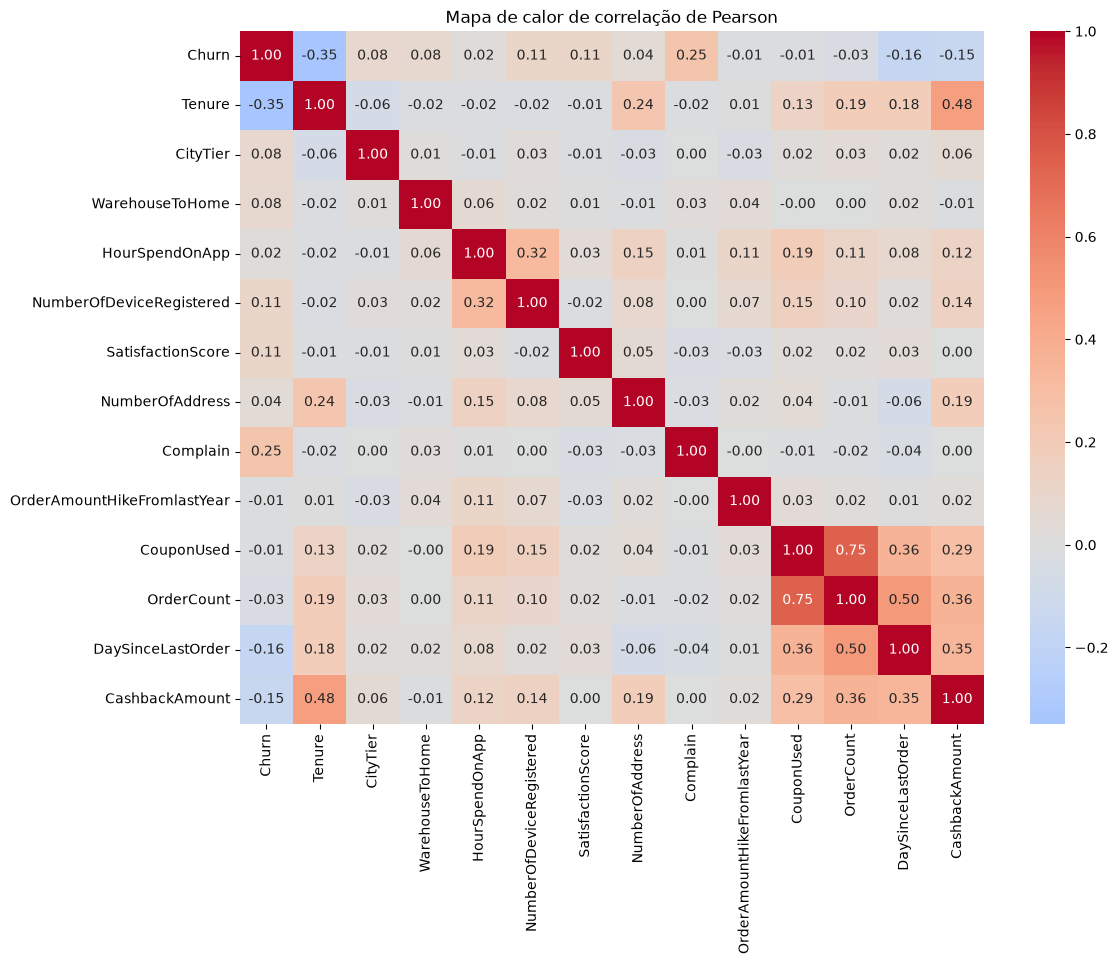

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: desbalanceamento da variável alvo
sns.countplot(x="Churn", data=df, ax=axes[0])
axes[0].set_title("Distribuição da variável alvo (Churn)")
total = len(df)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height() / total:.1%}",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

# Gráfico 2: distribuição do tempo de relacionamento
sns.histplot(df["Tenure"].dropna(), bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribuição de Tenure (meses como cliente)")

plt.tight_layout()
plt.show()

# Gráfico 3: mapa de calor de correlação de Pearson
plt.figure(figsize=(12, 9))
corr = df.drop(columns="CustomerID").corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Mapa de calor de correlação de Pearson")
plt.show()

### 1.2 Análise visual

In [ ]:
print("Linhas duplicadas:", df.duplicated().sum())
print("Duplicadas desconsiderando CustomerID:", df.drop(columns="CustomerID").duplicated().sum())

print("\nValores nulos por coluna:")
nulos = df.isnull().sum()
print(nulos[nulos > 0])

print("\nValores únicos das colunas categóricas:")
colunas_texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for col in colunas_texto:
    print(f"\n{col}:")
    print(df[col].value_counts())

Linhas duplicadas: 0
Duplicadas desconsiderando CustomerID: 556

Valores nulos por coluna:
Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64

Valores únicos das colunas categóricas:

PreferredLoginDevice:
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64

PreferredPaymentMode:
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64

Gender:
Gender
Male      3384
Female    2246
Name: count, dtype: int64

PreferedOrderCat:
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery         

## Fase 1: Análise Exploratória de Dados (EDA)

### 1.1 Qualidade dos dados: duplicadas, nulos e categorias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/ecommerce_churn.csv")

print("Linhas e colunas:", df.shape)
print()
df.info()
df.describe()

Linhas e colunas: (5630, 20)

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13 

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52815.500000,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.221492
std,1625.385339,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.193869
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51408.250000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,146.000000
50%,52815.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.000000
75%,54222.750000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.000000
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,325.000000


# Projeto Avaliativo: Predição de Churn em E-commerce

**Base escolhida:** Opção B (E-commerce Churn)
**Objetivo de negócio:** prever quais clientes estão prestes a abandonar a plataforma (Churn = 1) para oferecer cupons preventivos de retenção.
**Modelos:** KNN e Árvore de Decisão.